In [47]:
# Importing the required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Setting visualization style
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [48]:
# Loading the Titanic dataset

df = sns.load_dataset('titanic')

# Display the first five rows
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [49]:
# Display the number of rows and columns

print("Dataset Shape:", df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Display dataset information
df.info()

Dataset Shape: (891, 15)

Column Names:
['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891

In [50]:
df.head(10)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
5,0,3,male,NaN,0,0,8.4583,Q,Third,man,True,NaN,Queenstown,no,True
6,0,1,male,54.0,0,0,51.8625,S,First,man,True,E,Southampton,no,True
7,0,3,male,2.0,3,1,21.0750,S,Third,child,False,NaN,Southampton,no,False
8,1,3,female,27.0,0,2,11.1333,S,Third,woman,False,NaN,Southampton,yes,False
9,1,2,female,14.0,1,0,30.0708,C,Second,child,False,NaN,Cherbourg,yes,False


In [51]:
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [52]:
df.describe(include='object')


,sex,embarked,who,embark_town,alive
count,891,889,891,889,891
unique,2,3,3,3,2
top,male,S,man,Southampton,no
freq,577,644,537,644,549


In [53]:
# Checking missing values in each column

print(df.isnull().sum())

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64


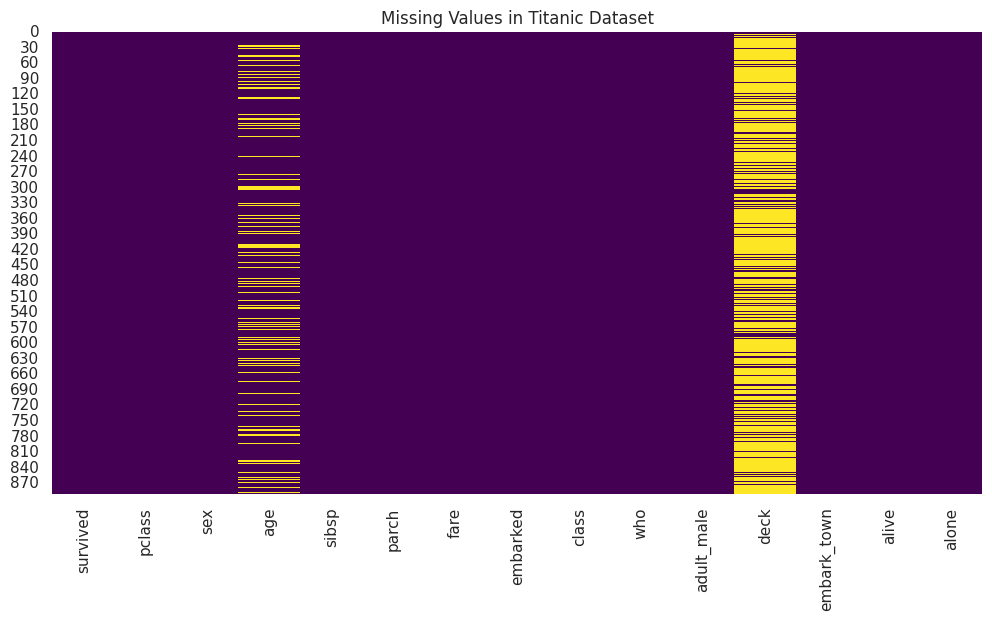

In [54]:
# Visualizing missing values

plt.figure(figsize=(12, 6))

sns.heatmap(df.isnull(), cbar=False, cmap='viridis')

plt.title('Missing Values in Titanic Dataset')
plt.show()

In [55]:
# Calculating missing value percentages

missing_percentage = (df.isnull().sum() / len(df)) * 100

print(missing_percentage.sort_values(ascending=False))

deck           77.216611
age            19.865320
embarked        0.224467
embark_town     0.224467
sex             0.000000
pclass          0.000000
survived        0.000000
fare            0.000000
parch           0.000000
sibsp           0.000000
class           0.000000
adult_male      0.000000
who             0.000000
alive           0.000000
alone           0.000000
dtype: float64


In [56]:
# Handling missing values

# Filling missing age values with median
df['age'] = df['age'].fillna(df['age'].median())

# Filling missing embarked values with mode
df['embarked'] = df['embarked'].fillna(df['embarked'].mode()[0])

# Dropping deck column
df.drop(columns=['deck'], inplace=True)

print("Missing values handled successfully!")


Missing values handled successfully!


In [57]:
# Filling missing embark_town values with mode

df['embark_town'] = df['embark_town'].fillna(df['embark_town'].mode()[0])

print("Missing values handled successfully!")

Missing values handled successfully!


In [58]:
# Checking missing values after cleaning

print(df.isnull().sum())

survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    0
alive          0
alone          0
dtype: int64


In [59]:
# Checking duplicate records

print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 116


In [60]:
# Removing duplicate records

df.drop_duplicates(inplace=True)

print("Dataset shape after removing duplicates:", df.shape)

Dataset shape after removing duplicates: (775, 14)


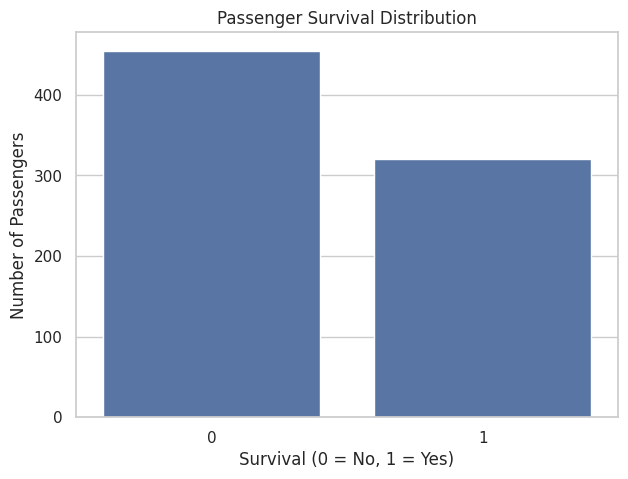

In [61]:
# Analyzing passenger survival

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='survived')

plt.title('Passenger Survival Distribution')
plt.xlabel('Survival (0 = No, 1 = Yes)')
plt.ylabel('Number of Passengers')

plt.show()

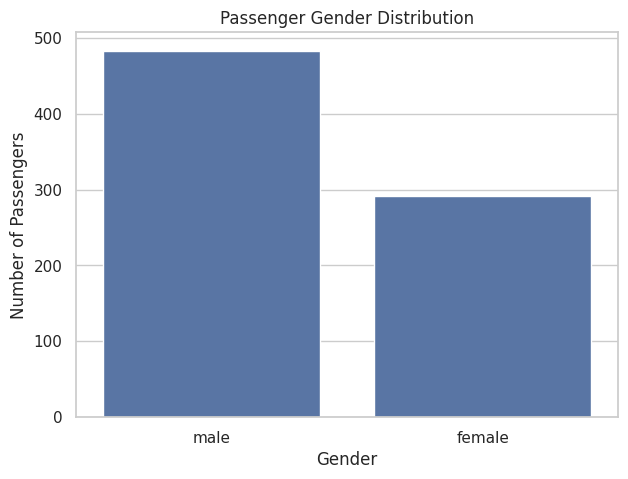

In [62]:
# Analyzing passenger gender distribution

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='sex')

plt.title('Passenger Gender Distribution')
plt.xlabel('Gender')
plt.ylabel('Number of Passengers')

plt.show()

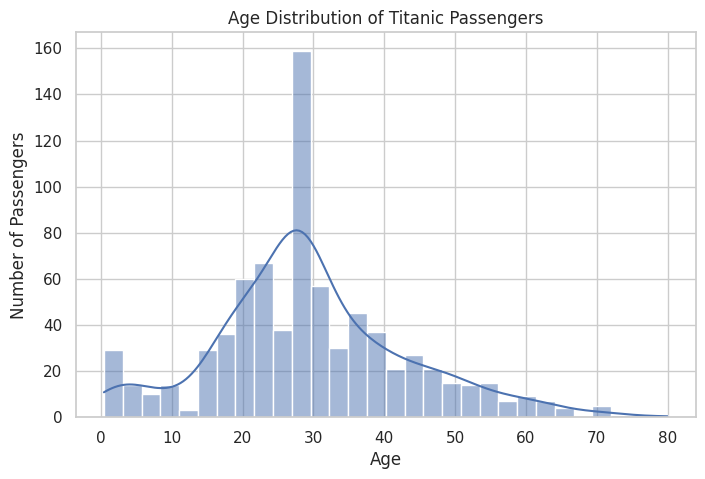

In [63]:
# Analyzing passenger age distribution

plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='age', bins=30, kde=True)

plt.title('Age Distribution of Titanic Passengers')
plt.xlabel('Age')
plt.ylabel('Number of Passengers')

plt.show()

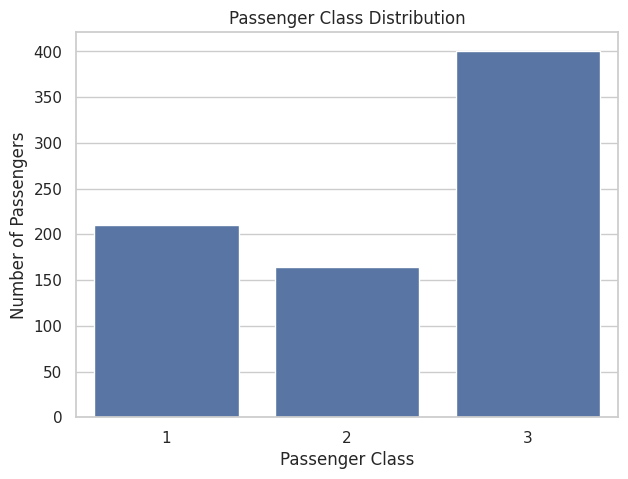

In [64]:
# Analyzing passenger class distribution

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='pclass')

plt.title('Passenger Class Distribution')
plt.xlabel('Passenger Class')
plt.ylabel('Number of Passengers')

plt.show()

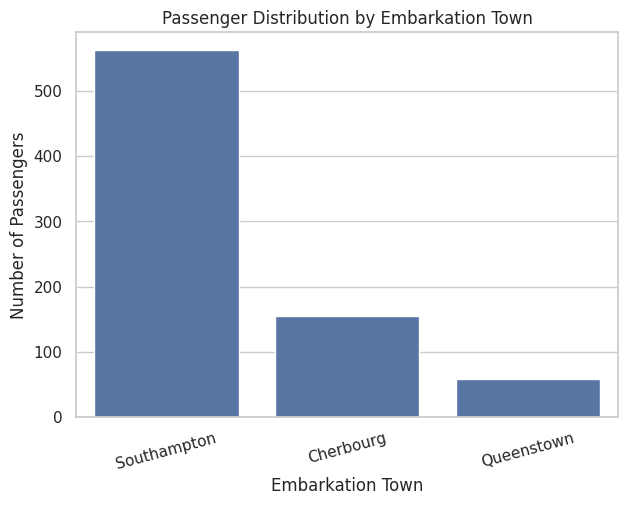

In [65]:
# Analyzing passenger embarkation towns

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='embark_town')

plt.title('Passenger Distribution by Embarkation Town')
plt.xlabel('Embarkation Town')
plt.ylabel('Number of Passengers')

plt.xticks(rotation=15)

plt.show()

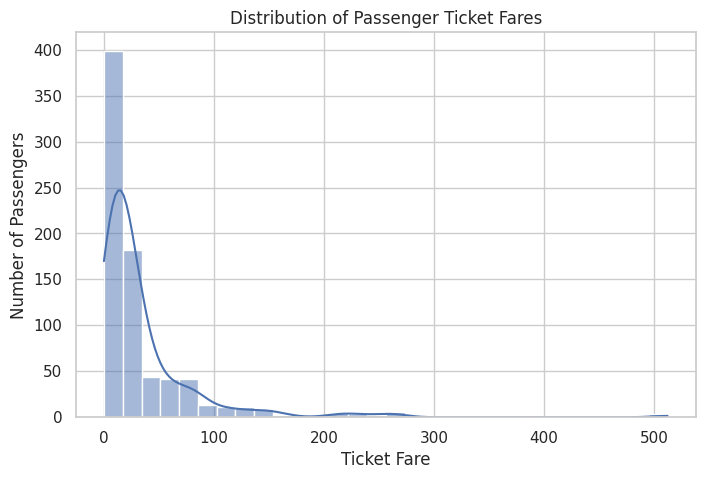

In [66]:
# Analyzing passenger fare distribution

plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='fare', bins=30, kde=True)

plt.title('Distribution of Passenger Ticket Fares')
plt.xlabel('Ticket Fare')
plt.ylabel('Number of Passengers')

plt.show()

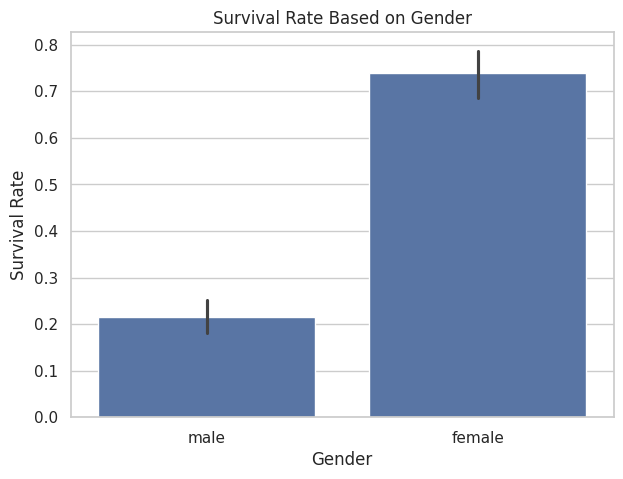

In [67]:
# Analyzing survival based on gender

plt.figure(figsize=(7, 5))

sns.barplot(data=df, x='sex', y='survived')

plt.title('Survival Rate Based on Gender')
plt.xlabel('Gender')
plt.ylabel('Survival Rate')

plt.show()

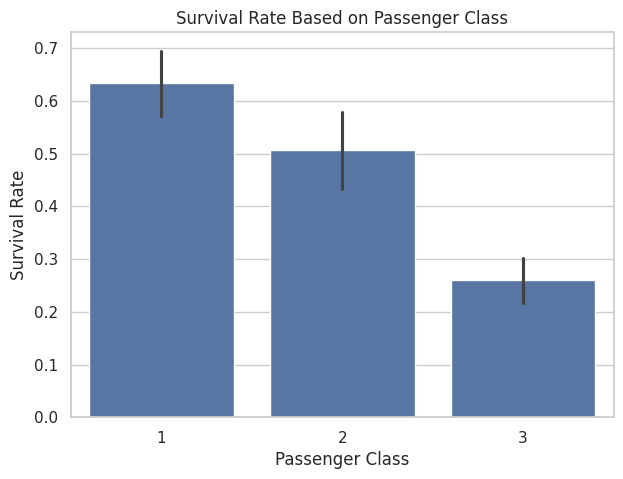

In [68]:
# Analyzing survival based on passenger class

plt.figure(figsize=(7, 5))

sns.barplot(data=df, x='pclass', y='survived')

plt.title('Survival Rate Based on Passenger Class')
plt.xlabel('Passenger Class')
plt.ylabel('Survival Rate')

plt.show()

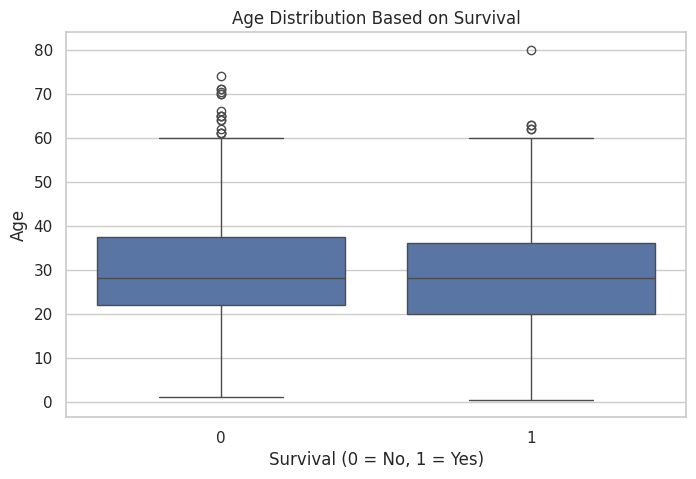

In [69]:
# Analyzing age distribution based on survival

plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='survived', y='age')

plt.title('Age Distribution Based on Survival')
plt.xlabel('Survival (0 = No, 1 = Yes)')
plt.ylabel('Age')

plt.show()

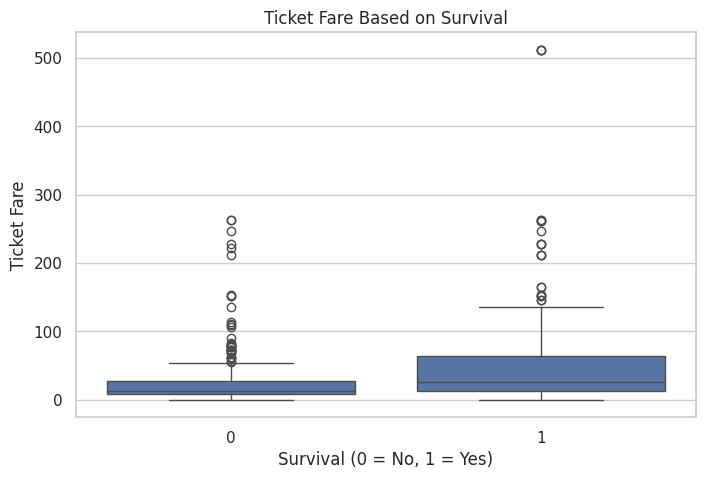

In [70]:
# Analyzing fare based on survival

plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='survived', y='fare')

plt.title('Ticket Fare Based on Survival')
plt.xlabel('Survival (0 = No, 1 = Yes)')
plt.ylabel('Ticket Fare')

plt.show()

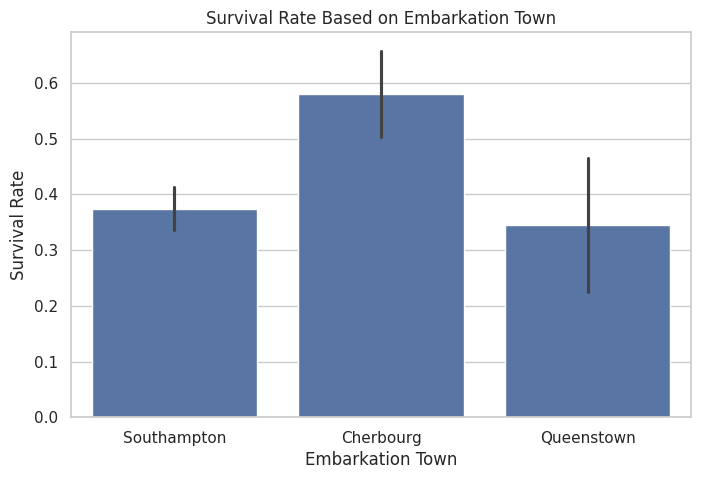

In [71]:
# Analyzing survival based on embarkation town

plt.figure(figsize=(8, 5))

sns.barplot(data=df, x='embark_town', y='survived')

plt.title('Survival Rate Based on Embarkation Town')
plt.xlabel('Embarkation Town')
plt.ylabel('Survival Rate')

plt.show()

In [72]:
# Calculating survival rates based on gender

gender_survival = df.groupby('sex')['survived'].mean() * 100

print("Survival Rate by Gender:")
print(gender_survival)

# Calculating survival rates based on passenger class

class_survival = df.groupby('pclass')['survived'].mean() * 100

print("\nSurvival Rate by Passenger Class:")
print(class_survival)

Survival Rate by Gender:
sex
female    73.972603
male      21.532091
Name: survived, dtype: float64

Survival Rate by Passenger Class:
pclass
1    63.333333
2    50.609756
3    25.935162
Name: survived, dtype: float64


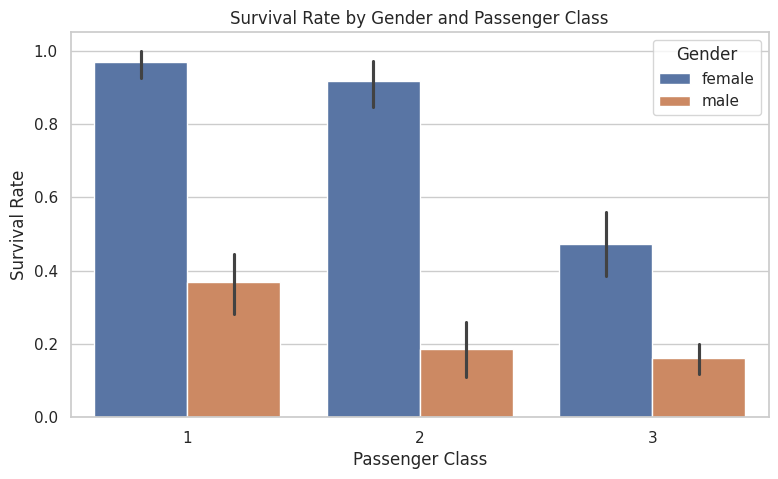

In [73]:
# Analyzing survival based on gender and passenger class

plt.figure(figsize=(9, 5))

sns.barplot(data=df, x='pclass', y='survived', hue='sex')

plt.title('Survival Rate by Gender and Passenger Class')
plt.xlabel('Passenger Class')
plt.ylabel('Survival Rate')
plt.legend(title='Gender')

plt.show()

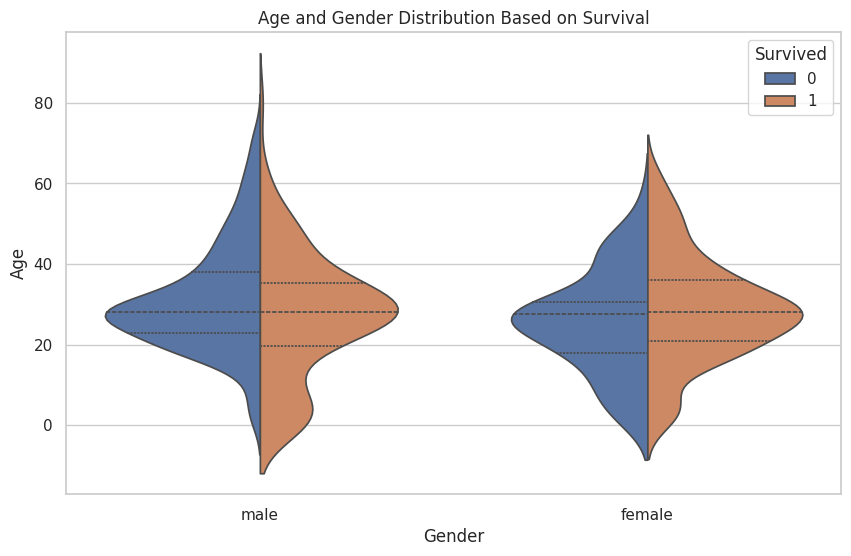

In [74]:
# Analyzing age and gender based on survival

plt.figure(figsize=(10, 6))

sns.violinplot(data=df, x='sex', y='age', hue='survived',
               split=True, inner='quart')

plt.title('Age and Gender Distribution Based on Survival')
plt.xlabel('Gender')
plt.ylabel('Age')
plt.legend(title='Survived')

plt.show()

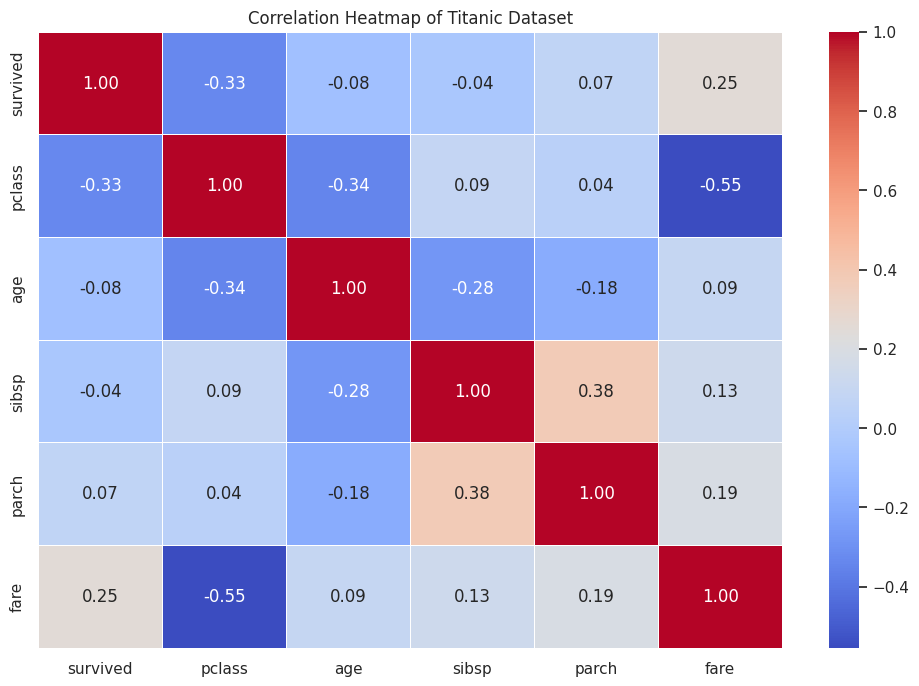

In [75]:
# Selecting numerical columns

numeric_df = df.select_dtypes(include=['number'])

# Calculating correlation matrix

correlation = numeric_df.corr()

# Visualizing correlation

plt.figure(figsize=(12, 8))

sns.heatmap(correlation, annot=True, cmap='coolwarm',
            fmt='.2f', linewidths=0.5)

plt.title('Correlation Heatmap of Titanic Dataset')

plt.show()

In [76]:
# Creating a family size column

df['family_size'] = df['sibsp'] + df['parch'] + 1

print(df[['sibsp', 'parch', 'family_size']].head())

   sibsp  parch  family_size
0      1      0            2
1      1      0            2
2      0      0            1
3      1      0            2
4      0      0            1


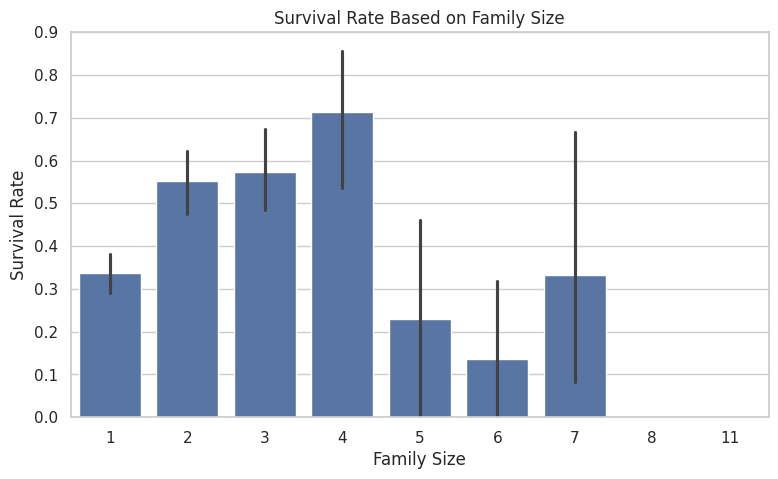

In [77]:
# Analyzing family size and survival

plt.figure(figsize=(9, 5))

sns.barplot(data=df, x='family_size', y='survived')

plt.title('Survival Rate Based on Family Size')
plt.xlabel('Family Size')
plt.ylabel('Survival Rate')

plt.show()

In [78]:
# Calculating survival rates based on family size

family_survival = df.groupby('family_size')['survived'].agg(
    ['count', 'sum', 'mean']
)

family_survival.columns = [
    'Total Passengers',
    'Survivors',
    'Survival Rate'
]

family_survival['Survival Rate'] *= 100

print(family_survival.round(2))

             Total Passengers  Survivors  Survival Rate
family_size                                            
1                         437        147          33.64
2                         154         85          55.19
3                         101         58          57.43
4                          28         20          71.43
5                          13          3          23.08
6                          22          3          13.64
7                          12          4          33.33
8                           6          0           0.00
11                          2          0           0.00


In [79]:
# Overall survival statistics

total_passengers = len(df)
total_survivors = df['survived'].sum()
total_deaths = total_passengers - total_survivors

survival_percentage = (total_survivors / total_passengers) * 100

print("Total Passengers:", total_passengers)
print("Total Survivors:", total_survivors)
print("Total Deaths:", total_deaths)
print("Overall Survival Rate:", round(survival_percentage, 2), "%")

Total Passengers: 775
Total Survivors: 320
Total Deaths: 455
Overall Survival Rate: 41.29 %


In [80]:
# Survival rate by different passenger characteristics

print("Survival Rate by Gender:")
print((df.groupby('sex')['survived'].mean() * 100).round(2))

print("\nSurvival Rate by Passenger Class:")
print((df.groupby('pclass')['survived'].mean() * 100).round(2))

print("\nSurvival Rate by Embarkation Town:")
print((df.groupby('embark_town')['survived'].mean() * 100).round(2))

Survival Rate by Gender:
sex
female    73.97
male      21.53
Name: survived, dtype: float64

Survival Rate by Passenger Class:
pclass
1    63.33
2    50.61
3    25.94
Name: survived, dtype: float64

Survival Rate by Embarkation Town:
embark_town
Cherbourg      58.06
Queenstown     34.48
Southampton    37.37
Name: survived, dtype: float64


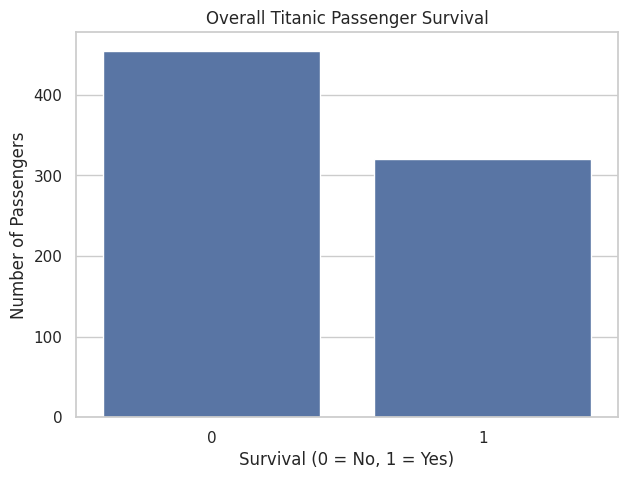

In [81]:
# Overall passenger survival visualization

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='survived')

plt.title('Overall Titanic Passenger Survival')
plt.xlabel('Survival (0 = No, 1 = Yes)')
plt.ylabel('Number of Passengers')

plt.show()

In [82]:
# Reloading the original Titanic dataset

df = sns.load_dataset('titanic')

# Handling missing values

df['age'] = df['age'].fillna(df['age'].median())

df['embarked'] = df['embarked'].fillna(
    df['embarked'].mode()[0]
)

df['embark_town'] = df['embark_town'].fillna(
    df['embark_town'].mode()[0]
)

# Removing deck column due to excessive missing values

df.drop(columns=['deck'], inplace=True)

# Creating family size column

df['family_size'] = df['sibsp'] + df['parch'] + 1

# Checking dataset size

print("Final Dataset Shape:", df.shape)
print("Total Passengers:", len(df))
print("Missing Values:", df.isnull().sum().sum())

Final Dataset Shape: (891, 15)
Total Passengers: 891
Missing Values: 0


In [83]:
# Final dataset verification

print("Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Dataset Shape: (891, 15)

Missing Values:
survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    0
alive          0
alone          0
family_size    0
dtype: int64

Duplicate Rows:
116


In [84]:
# Inspecting duplicate records

duplicate_records = df[df.duplicated(keep=False)]

print("Total duplicate-related records:", len(duplicate_records))

duplicate_records.head(10)

Total duplicate-related records: 174


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone,family_size
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,Southampton,no,True,1
23,1,1,male,28.0,0,0,35.5000,S,First,man,True,Southampton,yes,True,1
26,0,3,male,28.0,0,0,7.2250,C,Third,man,True,Cherbourg,no,True,1
28,1,3,female,28.0,0,0,7.8792,Q,Third,woman,False,Queenstown,yes,True,1
29,0,3,male,28.0,0,0,7.8958,S,Third,man,True,Southampton,no,True,1
32,1,3,female,28.0,0,0,7.7500,Q,Third,woman,False,Queenstown,yes,True,1
37,0,3,male,21.0,0,0,8.0500,S,Third,man,True,Southampton,no,True,1
42,0,3,male,28.0,0,0,7.8958,C,Third,man,True,Cherbourg,no,True,1
45,0,3,male,28.0,0,0,8.0500,S,Third,man,True,Southampton,no,True,1
46,0,3,male,28.0,1,0,15.5000,Q,Third,man,True,Queenstown,no,False,2


In [85]:
# Recalculating family size

df['family_size'] = df['sibsp'] + df['parch'] + 1

# Survival rate by family size

family_analysis = df.groupby('family_size')['survived'].agg(
    ['count', 'sum', 'mean']
)

family_analysis.columns = [
    'Total Passengers',
    'Survivors',
    'Survival Rate'
]

family_analysis['Survival Rate'] *= 100

print(family_analysis.round(2))

             Total Passengers  Survivors  Survival Rate
family_size                                            
1                         537        163          30.35
2                         161         89          55.28
3                         102         59          57.84
4                          29         21          72.41
5                          15          3          20.00
6                          22          3          13.64
7                          12          4          33.33
8                           6          0           0.00
11                          7          0           0.00


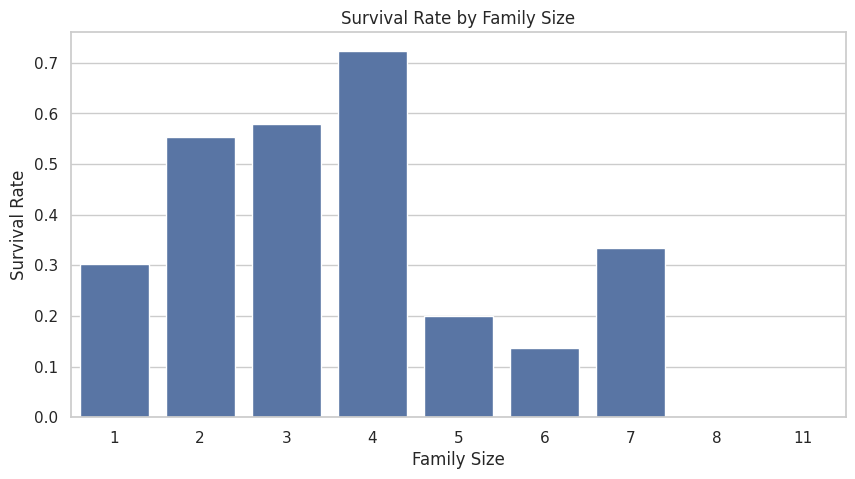

In [86]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=df,
    x='family_size',
    y='survived',
    errorbar=None
)

plt.title('Survival Rate by Family Size')
plt.xlabel('Family Size')
plt.ylabel('Survival Rate')
plt.show()